# R1-MC8 — Sensitivity of hub abundance and half-life to centrality cutoff

**Reviewer 1, comment 8:** Do hub-associated biochemical relationships persist when hubs are defined using alternative degree-centrality cutoffs?

This notebook is adapted from `figures/2-figure/2-figure.ipynb`. It preserves the **same input files, column names, original variables, `>=` hub definition, positive-value filtering, and Mann–Whitney U test**. Only the degree-centrality cutoff varies: **70th, 75th, 80th, 85th, 90th, and 95th percentiles**.

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import NullLocator
from scipy.stats import mannwhitneyu
from tqdm import trange
import matplotlib.colors as mcolors
from tqdm import tqdm, trange
from scipy.stats import mannwhitneyu
from scipy.stats import fisher_exact
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from typing import Dict, Optional
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

DATA_PATH2 = "../../18-finalize/processed-data/"
DATA_PATH3 = "../../17-meltome-atlas/processed-data/"
OUT_PATH   = "figures/"
MS_COLOR   = "#DDAA33"
Y2H_COLOR  = "#BB5566"

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titlepad": 25,
    "font.family": "sans-serif",
    "font.sans-serif": "Arial",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

In [2]:
# load the datasets with node centrality information and get nodes in both
ms_nodes = pd.read_pickle(f"{DATA_PATH2}20260210-s288c-ANnnotated-Yeast-Interactome.pkl")
y2h_nodes = pd.read_pickle(f"{DATA_PATH3}y2h-test-s288c-step17.pkl")
shared_nodes = set(ms_nodes["node"]) & set(y2h_nodes["node"])
print (f"A total of {len(shared_nodes)} nodes are shared between the MS and Y2H networks")

A total of 1465 nodes are shared between the MS and Y2H networks


In [7]:
# Determine which nodes are hubs based on percentile cutoff for degree centrality

cutoffs = [0.30, 0.25, 0.20, 0.15, 0.10, 0.05]

hub_groups = {}

for cut in cutoffs:

    ms_threshold = ms_nodes["degree_centrality"].quantile(1 - cut)
    ms_hubs = ms_nodes[ms_nodes["degree_centrality"] >= ms_threshold]
    ms_nothub = ms_nodes[ms_nodes["degree_centrality"] < ms_threshold]

    y2h_threshold = y2h_nodes["degree_centrality"].quantile(1 - cut)
    y2h_hubs = y2h_nodes[y2h_nodes["degree_centrality"] >= y2h_threshold]
    y2h_nothub = y2h_nodes[y2h_nodes["degree_centrality"] < y2h_threshold]

    percentile = int(round((1 - cut) * 100))

    # Store results for each cutoff
    hub_groups[percentile] = {
        "ms_hubs": ms_hubs,
        "ms_nothub": ms_nothub,
        "y2h_hubs": y2h_hubs,
        "y2h_nothub": y2h_nothub,
        "ms_threshold": ms_threshold,
        "y2h_threshold": y2h_threshold,
    }

    print(f"\nDegree centrality percentile: {percentile}")
    print(f"Threshold for defining a hub in MS data is {ms_threshold:.5f}; there are {len(ms_hubs)} hubs and {len(ms_nothub)} non hubs")
    print(f"Threshold for defining a hub in Y2H data is {y2h_threshold:.5f}; there are {len(y2h_hubs)} hubs and {len(y2h_nothub)} non hubs")


Degree centrality percentile: 70
Threshold for defining a hub in MS data is 0.00382; there are 1227 hubs and 2700 non hubs
Threshold for defining a hub in Y2H data is 0.00149; there are 629 hubs and 1389 non hubs

Degree centrality percentile: 75
Threshold for defining a hub in MS data is 0.00509; there are 998 hubs and 2929 non hubs
Threshold for defining a hub in Y2H data is 0.00149; there are 629 hubs and 1389 non hubs

Degree centrality percentile: 80
Threshold for defining a hub in MS data is 0.00688; there are 794 hubs and 3133 non hubs
Threshold for defining a hub in Y2H data is 0.00198; there are 426 hubs and 1592 non hubs

Degree centrality percentile: 85
Threshold for defining a hub in MS data is 0.00917; there are 591 hubs and 3336 non hubs
Threshold for defining a hub in Y2H data is 0.00198; there are 426 hubs and 1592 non hubs

Degree centrality percentile: 90
Threshold for defining a hub in MS data is 0.01182; there are 393 hubs and 3534 non hubs
Threshold for defining a

In [9]:

def bootstrap_ci_median(values, B=3_000, ci=95, random_state=27):
    """
    Nonparametric bootstrap CI for the median.

    values: 1D array-like
    B: number of bootstrap resamples
    ci: confidence level (e.g., 95)
    """
    vals = np.asarray(values)
    vals = vals[np.isfinite(vals)]
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(random_state)
    medians = np.empty(B, dtype=float)

    # Loop-based bootstrap to avoid huge memory allocations
    for b in trange(B, desc="Bootstrapping medians", leave=False):
        sample = rng.choice(vals, size=n, replace=True)
        medians[b] = np.median(sample)

    median_hat = np.median(vals)
    alpha = 100 - ci
    lower = np.percentile(medians, alpha / 2)
    upper = np.percentile(medians, 100 - alpha / 2)
    return median_hat, lower, upper


def clean_for_log(s):
    return (
        s.replace([np.inf, -np.inf], np.nan)
         .dropna()
         .loc[lambda x: x > 0]
    )


# ============================================================
# Abundance analysis across all degree-centrality cutoffs
# ============================================================

abundance_by_cutoff = {}
abundance_summary_by_cutoff = {}

for percentile in sorted(hub_groups):

    current = hub_groups[percentile]

    ms_nothub_vals = clean_for_log(
        current["ms_nothub"]["mean_molecules_per_cell"]
    )
    ms_hub_vals = clean_for_log(
        current["ms_hubs"]["mean_molecules_per_cell"]
    )
    y2h_nothub_vals = clean_for_log(
        current["y2h_nothub"]["mean_molecules_per_cell"]
    )
    y2h_hub_vals = clean_for_log(
        current["y2h_hubs"]["mean_molecules_per_cell"]
    )

    abundance_by_cutoff[percentile] = {
        "ms_hubs": ms_hub_vals,
        "ms_nothub": ms_nothub_vals,
        "y2h_hubs": y2h_hub_vals,
        "y2h_nothub": y2h_nothub_vals,
    }

    groups = [
        ("MS hubs",      ms_hub_vals,     MS_COLOR),
        ("MS non-hubs",  ms_nothub_vals,  MS_COLOR),
        ("Y2H hubs",     y2h_hub_vals,    Y2H_COLOR),
        ("Y2H non-hubs", y2h_nothub_vals, Y2H_COLOR),
    ]

    abundance_summary_by_cutoff[percentile] = {}

    print(f"\n{'='*55}")
    print(f"Degree-centrality cutoff: {percentile}th percentile")
    print(f"{'='*55}")

    for key, (label, vals, color) in zip(
        ["ms_hubs", "ms_nothub", "y2h_hubs", "y2h_nothub"],
        groups
    ):
        m, lo, hi = bootstrap_ci_median(
            vals, B=3_000, ci=95, random_state=42
        )

        abundance_summary_by_cutoff[percentile][key] = {
            "median": m,
            "ci_lower": lo,
            "ci_upper": hi,
            "n": len(vals),
            "color": color,
        }

        print(
            f"{label}: median={m:.2f}, "
            f"95% CI=({lo:.2f}, {hi:.2f}), "
            f"n={len(vals)})"
        )


Degree-centrality cutoff: 70th percentile


MS hubs: median=6120.50, 95% CI=(5649.99, 6851.19), n=1200)


MS non-hubs: median=3094.00, 95% CI=(2973.00, 3198.00), n=2653)


Y2H hubs: median=3452.00, 95% CI=(3036.00, 3833.00), n=607)


Y2H non-hubs: median=3099.00, 95% CI=(2889.00, 3278.00), n=1271)

Degree-centrality cutoff: 75th percentile


MS hubs: median=6623.00, 95% CI=(5886.62, 7499.00), n=972)


... (15 outputs left out)

MS hubs: median=15864.00, 95% CI=(9369.01, 35358.50), n=204)


MS non-hubs: median=3683.00, 95% CI=(3526.00, 3850.00), n=3649)


Y2H hubs: median=3212.50, 95% CI=(2577.81, 4224.00), n=130)


Y2H non-hubs: median=3181.50, 95% CI=(3015.94, 3390.50), n=1748)


In [11]:

from scipy.stats import mannwhitneyu
import pandas as pd

# ============================================================
# Mann–Whitney U-tests across all hub cutoffs
# ============================================================

abundance_mwu_by_cutoff = {}
mwu_results = []

for percentile in sorted(abundance_by_cutoff):

    current = abundance_by_cutoff[percentile]

    ms_hub_vals = current["ms_hubs"]
    ms_nothub_vals = current["ms_nothub"]

    y2h_hub_vals = current["y2h_hubs"]
    y2h_nothub_vals = current["y2h_nothub"]

    # Original Figure 2 statistical test
    ms_u, ms_p = mannwhitneyu(
        ms_hub_vals, ms_nothub_vals, alternative="greater"
    )

    y2h_u, y2h_p = mannwhitneyu(
        y2h_hub_vals, y2h_nothub_vals, alternative="greater"
    )

    # Store results
    abundance_mwu_by_cutoff[percentile] = {
        "ms_u": ms_u,
        "ms_p": ms_p,
        "y2h_u": y2h_u,
        "y2h_p": y2h_p,
    }

    # Create a summary table
    for network, hubs, nonhubs, u, p in [
        ("AE-MS", ms_hub_vals, ms_nothub_vals, ms_u, ms_p),
        ("Y2H", y2h_hub_vals, y2h_nothub_vals, y2h_u, y2h_p),
    ]:
        mwu_results.append({
            "Percentile": percentile,
            "Network": network,
            "Hub n": len(hubs),
            "Non-hub n": len(nonhubs),
            "Hub median": hubs.median(),
            "Non-hub median": nonhubs.median(),
            "U statistic": u,
            "p-value": p,
        })

abundance_mwu_df = pd.DataFrame(mwu_results)

display(abundance_mwu_df)


,Percentile,Network,Hub n,Non-hub n,Hub median,Non-hub median,U statistic,p-value
0,70,AE-MS,1200,2653,6120.5,3094.0,2251400.0,7.703787e-95
1,70,Y2H,607,1271,3452.0,3099.0,402564.0,6.302337e-02
2,75,AE-MS,972,2881,6623.0,3184.0,1997583.0,1.342752e-88
3,75,Y2H,607,1271,3452.0,3099.0,402564.0,6.302337e-02
4,80,AE-MS,770,3083,7551.0,3262.0,1737003.0,1.348152e-88
5,80,Y2H,414,1464,3425.0,3134.5,315872.5,9.402388e-02
6,85,AE-MS,571,3282,8379.0,3418.5,1389437.0,3.055366e-76
7,85,Y2H,414,1464,3425.0,3134.5,315872.5,9.402388e-02
8,90,AE-MS,385,3468,9306.0,3532.0,1023419.0,1.772056e-66
9,90,Y2H,220,1658,3299.5,3175.0,185540.5,3.379262e-01


### Cell 3 calculated bootstrap confidence intervals for individual group medians. Our sensitivity figure needs confidence intervals for the ratio of those medians. We will calculate those separately using the same nonparametric bootstrap approach with 3,000 resamples.

,Percentile,Network,Hub n,Non-hub n,Hub median,Non-hub median,Ratio,Percent change (%),Log2 median ratio,CI lower,CI upper
0,70,AE-MS,1200,2653,6120.50,3094.00,1.978,+97.82,0.984,0.872,1.163
1,70,Y2H,607,1271,3452.00,3099.00,1.114,+11.39,0.156,-0.019,0.340
2,75,AE-MS,972,2881,6623.00,3184.00,2.080,+108.01,1.057,0.876,1.232
3,75,Y2H,607,1271,3452.00,3099.00,1.114,+11.39,0.156,-0.019,0.340
4,80,AE-MS,770,3083,7551.00,3262.00,2.315,+131.48,1.211,1.030,1.373
5,80,Y2H,414,1464,3425.00,3134.50,1.093,+9.27,0.128,-0.096,0.323
6,85,AE-MS,571,3282,8379.00,3418.50,2.451,+145.11,1.293,1.097,1.550
7,85,Y2H,414,1464,3425.00,3134.50,1.093,+9.27,0.128,-0.096,0.323
8,90,AE-MS,385,3468,9306.00,3532.00,2.635,+163.48,1.398,1.103,1.698
9,90,Y2H,220,1658,3299.50,3175.00,1.039,+3.92,0.055,-0.239,0.332


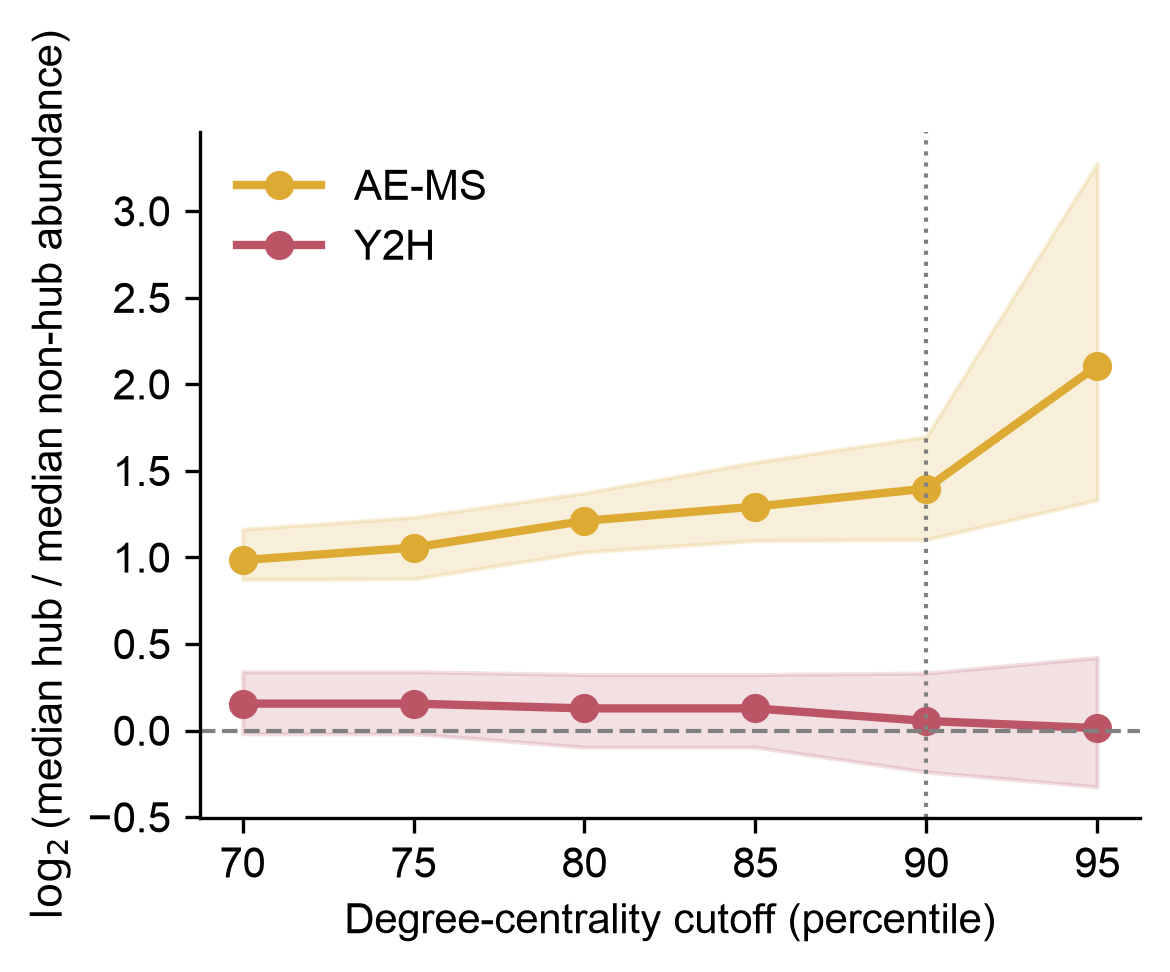

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Bootstrap 95% CI for log2 median ratio
# ============================================================

def bootstrap_ci_log2_ratio(hub_vals, nonhub_vals, B=3_000,
                            ci=95, random_state=42):

    hubs = np.asarray(hub_vals, dtype=float)
    nonhubs = np.asarray(nonhub_vals, dtype=float)

    # Observed median ratio
    ratio = np.log2(np.median(hubs) / np.median(nonhubs))

    rng = np.random.default_rng(random_state)
    ratios = np.empty(B, dtype=float)

    for b in range(B):
        hub_sample = rng.choice(hubs, size=len(hubs), replace=True)
        nonhub_sample = rng.choice(nonhubs, size=len(nonhubs), replace=True)

        ratios[b] = np.log2(
            np.median(hub_sample) / np.median(nonhub_sample)
        )

    alpha = 100 - ci
    lower = np.percentile(ratios, alpha / 2)
    upper = np.percentile(ratios, 100 - alpha / 2)

    return ratio, lower, upper



# ============================================================
# Calculate abundance median ratios across all cutoffs
# ============================================================

abundance_ratio_results = []

for percentile in sorted(abundance_by_cutoff):

    current = abundance_by_cutoff[percentile]

    for network, prefix in [("AE-MS", "ms"), ("Y2H", "y2h")]:

        hubs = current[f"{prefix}_hubs"]
        nonhubs = current[f"{prefix}_nothub"]

        # Original median values
        hub_median = np.median(hubs)
        nonhub_median = np.median(nonhubs)

        # Ratio and percent change
        ratio_raw = hub_median / nonhub_median
        percent_change = (ratio_raw - 1) * 100

        # Bootstrap log2 median ratio and 95% CI
        ratio, lower, upper = bootstrap_ci_log2_ratio(
            hubs, nonhubs, B=3_000, ci=95, random_state=42
        )

        abundance_ratio_results.append({
            "Percentile": percentile,
            "Network": network,
            "Hub n": len(hubs),
            "Non-hub n": len(nonhubs),
            "Hub median": hub_median,
            "Non-hub median": nonhub_median,
            "Ratio": ratio_raw,
            "Percent change (%)": percent_change,
            "Log2 median ratio": ratio,
            "CI lower": lower,
            "CI upper": upper,
        })

abundance_ratio_df = pd.DataFrame(abundance_ratio_results)

display(
    abundance_ratio_df.style.format({
        "Hub median": "{:.2f}",
        "Non-hub median": "{:.2f}",
        "Ratio": "{:.3f}",
        "Percent change (%)": "{:+.2f}",
        "Log2 median ratio": "{:.3f}",
        "CI lower": "{:.3f}",
        "CI upper": "{:.3f}",
    })
)

# ============================================================
# Plot abundance sensitivity analysis
# ============================================================

fig, ax = plt.subplots(figsize=(4, 3))

for network, color in [
    ("AE-MS", MS_COLOR),
    ("Y2H", Y2H_COLOR),
]:
    data = abundance_ratio_df[
        abundance_ratio_df["Network"] == network
    ].sort_values("Percentile")

    x = data["Percentile"].to_numpy()
    y = data["Log2 median ratio"].to_numpy()
    lower = data["CI lower"].to_numpy()
    upper = data["CI upper"].to_numpy()

    ax.plot(
        x, y,
        marker="o",
        linewidth=2,
        markersize=6,
        color=color,
        label=network
    )

    ax.fill_between(
        x, lower, upper,
        color=color,
        alpha=0.18
    )

# Reference lines
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(90, color="gray", linestyle=":", linewidth=1)

ax.set_xticks(sorted(abundance_by_cutoff))
ax.set_xlabel("Degree-centrality cutoff (percentile)")
ax.set_ylabel(
    r"$\log_2$(median hub / median non-hub abundance)"
)

ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    "R1-MC8-A.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()


In [18]:

# ============================================================
# Protein half-life analysis across all degree-centrality cutoffs
# ============================================================

halflife_by_cutoff = {}
halflife_summary_by_cutoff = {}

for percentile in sorted(hub_groups):

    current = hub_groups[percentile]

    ms_nothub_vals = clean_for_log(
        current["ms_nothub"]["Villen_halflife_min"]
    )
    ms_hub_vals = clean_for_log(
        current["ms_hubs"]["Villen_halflife_min"]
    )
    y2h_nothub_vals = clean_for_log(
        current["y2h_nothub"]["Villen_halflife_min"]
    )
    y2h_hub_vals = clean_for_log(
        current["y2h_hubs"]["Villen_halflife_min"]
    )

    halflife_by_cutoff[percentile] = {
        "ms_hubs": ms_hub_vals,
        "ms_nothub": ms_nothub_vals,
        "y2h_hubs": y2h_hub_vals,
        "y2h_nothub": y2h_nothub_vals,
    }

    groups = [
        ("MS hubs",      ms_hub_vals,     MS_COLOR),
        ("MS non-hubs",  ms_nothub_vals,  MS_COLOR),
        ("Y2H hubs",     y2h_hub_vals,    Y2H_COLOR),
        ("Y2H non-hubs", y2h_nothub_vals, Y2H_COLOR),
    ]

    halflife_summary_by_cutoff[percentile] = {}

    print(f"\n{'='*55}")
    print(f"Degree-centrality cutoff: {percentile}th percentile")
    print(f"{'='*55}")

    for key, (label, vals, color) in zip(
        ["ms_hubs", "ms_nothub", "y2h_hubs", "y2h_nothub"],
        groups
    ):
        m, lo, hi = bootstrap_ci_median(
            vals, B=3_000, ci=95, random_state=42
        )

        halflife_summary_by_cutoff[percentile][key] = {
            "median": m,
            "ci_lower": lo,
            "ci_upper": hi,
            "n": len(vals),
            "color": color,
        }

        print(
            f"{label}: median={m:.2f} min, "
            f"95% CI=({lo:.2f}, {hi:.2f}), "
            f"n={len(vals)}"
        )



Degree-centrality cutoff: 70th percentile


MS hubs: median=118.20 min, 95% CI=(113.40, 121.80), n=1026


MS non-hubs: median=136.20 min, 95% CI=(133.20, 139.20), n=1684


Y2H hubs: median=135.60 min, 95% CI=(131.70, 141.00), n=392


Y2H non-hubs: median=133.80 min, 95% CI=(129.00, 138.60), n=787

Degree-centrality cutoff: 75th percentile


MS hubs: median=114.60 min, 95% CI=(109.80, 118.80), n=847


... (15 outputs left out)

MS hubs: median=90.60 min, 95% CI=(89.40, 91.20), n=183


MS non-hubs: median=132.60 min, 95% CI=(130.80, 135.60), n=2527


Y2H hubs: median=140.40 min, 95% CI=(133.20, 153.00), n=81


Y2H non-hubs: median=134.10 min, 95% CI=(130.50, 137.71), n=1098


In [23]:

from scipy.stats import mannwhitneyu
import pandas as pd

# ============================================================
# Mann–Whitney U-tests across all hub cutoffs
# ============================================================

halflife_mwu_by_cutoff = {}
halflife_mwu_results = []

for percentile in sorted(halflife_by_cutoff):

    current = halflife_by_cutoff[percentile]
    halflife_mwu_by_cutoff[percentile] = {}

    for network, prefix in [("AE-MS", "ms"), ("Y2H", "y2h")]:

        hubs = current[f"{prefix}_hubs"]
        nonhubs = current[f"{prefix}_nothub"]

        # one-sided test (hubs lower)
        u_less, p_less = mannwhitneyu(
            hubs, nonhubs, alternative="less"
        )

        halflife_mwu_by_cutoff[percentile][network] = {
            "u_less": u_less,
            "p_less": p_less,
        }

        halflife_mwu_results.append({
            "Percentile": percentile,
            "Network": network,
            "Hub n": len(hubs),
            "Non-hub n": len(nonhubs),
            "Hub median": np.median(hubs),
            "Non-hub median": np.median(nonhubs),
            "U statistic": u_less,
            "p-value (less)": p_less,
        })

halflife_mwu_df = pd.DataFrame(halflife_mwu_results)

display(
    halflife_mwu_df.style.format({
        "Hub median": "{:.2f}",
        "Non-hub median": "{:.2f}",
        "U statistic": "{:.2f}",
        "p-value (less)": "{:.3e}",
    })
)


,Percentile,Network,Hub n,Non-hub n,Hub median,Non-hub median,U statistic,p-value (less)
0,70,AE-MS,1026,1684,118.20,136.20,674780.00,5.242e-22
1,70,Y2H,392,787,135.60,133.80,161867.00,9.166e-01
2,75,AE-MS,847,1863,114.60,136.80,588399.00,1.157e-26
3,75,Y2H,392,787,135.60,133.80,161867.00,9.166e-01
4,80,AE-MS,681,2029,110.40,135.00,507283.00,1.359e-25
5,80,Y2H,273,906,138.00,133.80,132820.00,9.683e-01
6,85,AE-MS,507,2203,102.60,133.80,394143.50,2.221e-25
7,85,Y2H,273,906,138.00,133.80,132820.00,9.683e-01
8,90,AE-MS,340,2370,91.50,134.10,230247.50,8.586e-38
9,90,Y2H,135,1044,142.20,133.80,80243.00,9.957e-01


,Percentile,Network,Hub n,Non-hub n,Hub median,Non-hub median,Ratio,Percent change (%),Log2 median ratio,CI lower,CI upper
0,70,AE-MS,1026,1684,118.20,136.20,0.868,-13.22,-0.204,-0.267,-0.155
1,70,Y2H,392,787,135.60,133.80,1.013,+1.35,0.019,-0.048,0.099
2,75,AE-MS,847,1863,114.60,136.80,0.838,-16.23,-0.255,-0.324,-0.193
3,75,Y2H,392,787,135.60,133.80,1.013,+1.35,0.019,-0.048,0.099
4,80,AE-MS,681,2029,110.40,135.00,0.818,-18.22,-0.290,-0.367,-0.206
5,80,Y2H,273,906,138.00,133.80,1.031,+3.14,0.045,-0.029,0.139
6,85,AE-MS,507,2203,102.60,133.80,0.767,-23.32,-0.383,-0.521,-0.254
7,85,Y2H,273,906,138.00,133.80,1.031,+3.14,0.045,-0.029,0.139
8,90,AE-MS,340,2370,91.50,134.10,0.682,-31.77,-0.551,-0.585,-0.517
9,90,Y2H,135,1044,142.20,133.80,1.063,+6.28,0.088,-0.006,0.195


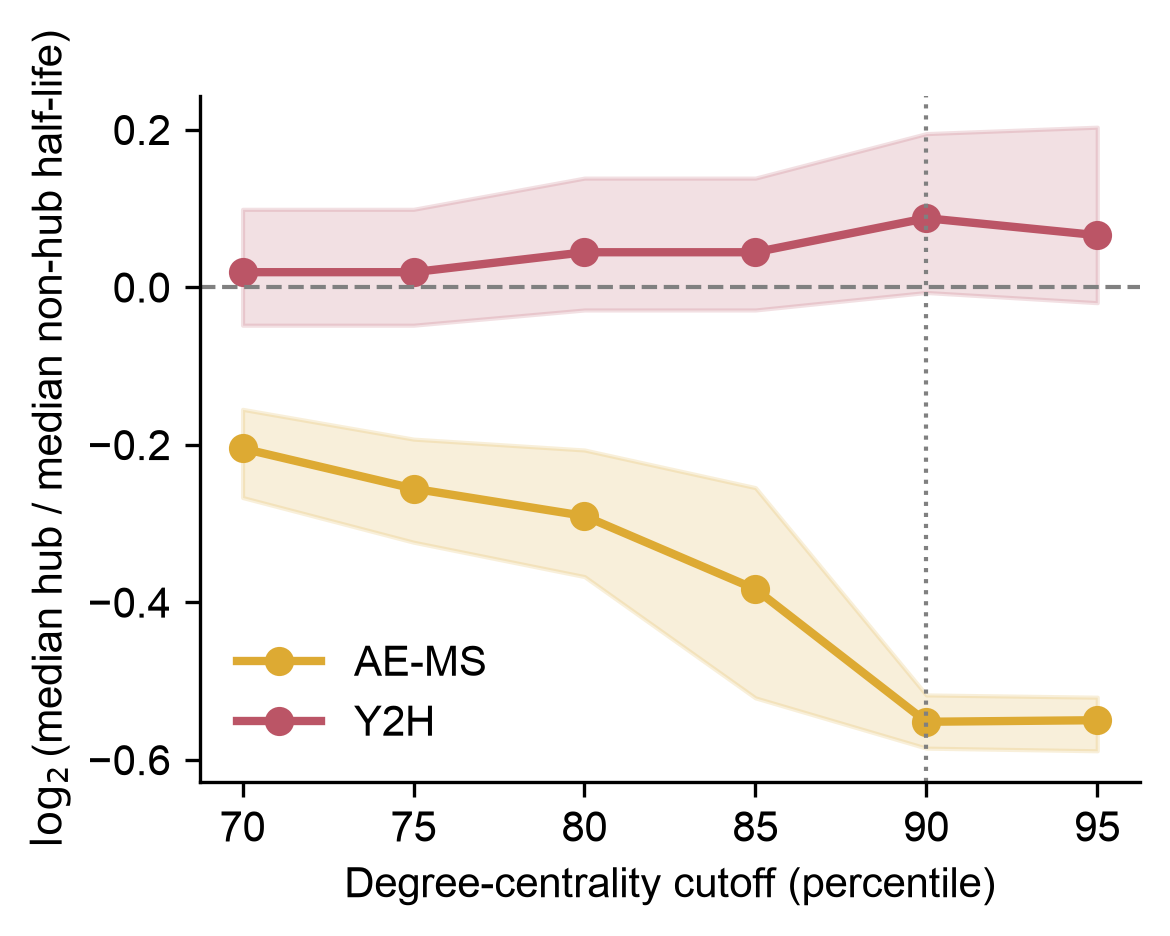

In [20]:

# ============================================================
# Calculate half-life median ratios across all cutoffs
# ============================================================

halflife_ratio_results = []

for percentile in sorted(halflife_by_cutoff):

    current = halflife_by_cutoff[percentile]

    for network, prefix in [("AE-MS", "ms"), ("Y2H", "y2h")]:

        hubs = current[f"{prefix}_hubs"]
        nonhubs = current[f"{prefix}_nothub"]

        # Original median values
        hub_median = np.median(hubs)
        nonhub_median = np.median(nonhubs)

        # Ratio and percent change
        ratio_raw = hub_median / nonhub_median
        percent_change = (ratio_raw - 1) * 100

        # Bootstrap log2 median ratio and 95% CI
        ratio, lower, upper = bootstrap_ci_log2_ratio(
            hubs, nonhubs, B=3_000, ci=95, random_state=42
        )

        halflife_ratio_results.append({
            "Percentile": percentile,
            "Network": network,
            "Hub n": len(hubs),
            "Non-hub n": len(nonhubs),
            "Hub median": hub_median,
            "Non-hub median": nonhub_median,
            "Ratio": ratio_raw,
            "Percent change (%)": percent_change,
            "Log2 median ratio": ratio,
            "CI lower": lower,
            "CI upper": upper,
        })

halflife_ratio_df = pd.DataFrame(halflife_ratio_results)

display(
    halflife_ratio_df.style.format({
        "Hub median": "{:.2f}",
        "Non-hub median": "{:.2f}",
        "Ratio": "{:.3f}",
        "Percent change (%)": "{:+.2f}",
        "Log2 median ratio": "{:.3f}",
        "CI lower": "{:.3f}",
        "CI upper": "{:.3f}",
    })
)


# ============================================================
# Plot half-life sensitivity analysis
# ============================================================

fig, ax = plt.subplots(figsize=(4, 3))

for network, color in [
    ("AE-MS", MS_COLOR),
    ("Y2H", Y2H_COLOR),
]:
    data = halflife_ratio_df[
        halflife_ratio_df["Network"] == network
    ].sort_values("Percentile")

    x = data["Percentile"].to_numpy()
    y = data["Log2 median ratio"].to_numpy()
    lower = data["CI lower"].to_numpy()
    upper = data["CI upper"].to_numpy()

    ax.plot(
        x, y,
        marker="o",
        linewidth=2,
        markersize=6,
        color=color,
        label=network
    )

    ax.fill_between(
        x, lower, upper,
        color=color,
        alpha=0.18
    )

# Reference lines
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(90, color="gray", linestyle=":", linewidth=1)

ax.set_xticks(sorted(halflife_by_cutoff))
ax.set_xlabel("Degree-centrality cutoff (percentile)")
ax.set_ylabel(
    r"$\log_2$(median hub / median non-hub half-life)"
)

ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    "R1-MC8-B.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()
